# IEEE-118: independent evaluation scenarios for PF and masked-voltage SE

This notebook loads the fine-tuned 250,000-scenario IEEE-118 **PowerFlow** checkpoint and its saved normalizer from [gridfm/genco-pf-transfer](https://huggingface.co/gridfm/genco-pf-transfer). It evaluates the two locally generated datasets in `datakit_out` and `datakit_out_aged01`; it does not download or use the Hugging Face evaluation data. Each dataset is evaluated twice:

- **PF:** Graphkit's PowerFlow task transform applies the checkpoint's standard power-flow masks.
- **SE:** the same PF checkpoint estimates voltages after 10% of bus `Vm` and 10% of bus `Va` measurements are hidden independently. Other bus, generator, and branch measurements remain available, as in the previous masked-voltage experiment. This is a measurement-masking experiment, not a separately trained state-estimation model or Graphkit's noisy StateEstimation task.

The standard runs save one row per bus with dataset and scenario identity, ground truth, raw model predictions, and voltage-mask flags. `Vm` is in p.u., `Va` in degrees, and `Pg`/`Qg` in MW/Mvar. Predictions for known (unmasked) values are saved as emitted by the model; they are not replaced with ground truth. Later sections compare the signed-error distributions and evaluate hidden aging, where the model receives original line impedances for aged-network observations.

Run from this repository's root or `src/` directory in the provided environment. The first run downloads only the model artifacts and may build Graphkit's processed dataset caches. Parquet outputs and histogram PNGs are written under `src/results/local_predictions/`.


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq
import torch
import yaml
from huggingface_hub import hf_hub_download
from torch_geometric.data import Batch
from tqdm.auto import tqdm

from gridfm_graphkit.cli import _normalize_loaded_state_dict_keys
from gridfm_graphkit.datasets.globals import (
    B_ON,
    C0_H,
    C2_H,
    G_ON,
    PQ_H,
    PV_H,
    REF_H,
    VA_H,
    VM_H,
    PG_OUT,
    QG_OUT,
    VA_OUT,
    VM_OUT,
    YFF_TT_R,
    YFT_TF_I,
    QG_H,
)
from gridfm_graphkit.datasets.powergrid_hetero_dataset import HeteroGridDatasetDisk
from gridfm_graphkit.datasets.transforms import (
    RemoveInactiveBranches,
    RemoveInactiveGenerators,
)
from gridfm_graphkit.io.param_handler import (
    NestedNamespace,
    get_task_transforms,
    load_model,
    load_normalizer,
)

MODEL_REPO_ID = "gridfm/genco-pf-transfer"
MODEL_REVISION = "main"
RUN_DIR = Path("finetune/case118_250000")
PROJECT_DIR = Path(".") if Path("datakit_out").is_dir() else Path("src")
NORMALIZER_NETWORK = "case118_ieee"
DATASET_ROOTS = {
    "case118_ieee": PROJECT_DIR / "datakit_out/case118_ieee",
    "case118_aged01": PROJECT_DIR / "datakit_out_aged01/case118_aged01",
}
OUTPUT_DIR = PROJECT_DIR / "results/local_predictions"
BATCH_SIZE = 16
SEED = 42
SE_MASK_FRACTION = 0.10
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Inference device: {DEVICE}")

Inference device: cuda


## 1. Load the matched model artifacts and local datasets

The checkpoint, YAML, and normalizer come from the same fine-tuning run. The evaluation data come exclusively from the locally generated `datakit_out/case118_ieee` and `datakit_out_aged01/case118_aged01` directories. The aged network uses the IEEE-118 normalizer because it has the same feature schema and topology dimensions.


In [2]:
artifact_paths = {
    key: hf_hub_download(
        MODEL_REPO_ID,
        f"{RUN_DIR}/{filename}",
        revision=MODEL_REVISION,
    )
    for key, filename in {
        "checkpoint": "best_model_state_dict.pt",
        "config": "case118_250000.yaml",
        "normalizer": "normalizer_stats.pt",
    }.items()
}
with open(artifact_paths["config"], encoding="utf-8") as handle:
    args = NestedNamespace(**yaml.safe_load(handle))

saved_stats = torch.load(
    artifact_paths["normalizer"],
    map_location="cpu",
    weights_only=True,
)
normalizer = load_normalizer(args)
normalizer.fit_from_dict(saved_stats[NORMALIZER_NETWORK])

required_tables = ["bus_data.parquet", "gen_data.parquet", "branch_data.parquet"]
for dataset_name, root in DATASET_ROOTS.items():
    missing = [name for name in required_tables if not (root / "raw" / name).exists()]
    if missing:
        raise FileNotFoundError(f"{dataset_name} is missing raw tables: {missing}")

datasets = {
    dataset_name: HeteroGridDatasetDisk(
        root=str(root),
        data_normalizer=normalizer,
        transform=None,
        stream_partitions=getattr(args.data, "stream_partitions", "auto"),
    )
    for dataset_name, root in DATASET_ROOTS.items()
}

model = load_model(args)
state = torch.load(
    artifact_paths["checkpoint"],
    map_location="cpu",
    weights_only=True,
)
state = _normalize_loaded_state_dict_keys(state)
model.load_state_dict(
    {key.removeprefix("model."): value for key, value in state.items()},
    strict=True,
)
model.to(DEVICE).eval()
for dataset_name, dataset in datasets.items():
    print(
        f"Loaded {len(dataset):,} scenarios from {DATASET_ROOTS[dataset_name] / 'raw'}"
    )

Loaded 99,613 scenarios from datakit_out/case118_ieee/raw
Loaded 99,603 scenarios from datakit_out_aged01/case118_aged01/raw


## 2. Define PF and SE inputs

PF uses Graphkit's registered PowerFlow transform, including removal of inactive equipment and the task's standard masks. For SE, inactive equipment is removed first; a fixed seed derived from each dataset index chooses the hidden voltage measurements. The target `y` tensors are preserved before input masking. The per-scenario seed makes SE masks independent of batch size and execution order.


In [3]:
pf_transform = get_task_transforms(args)
remove_branches = RemoveInactiveBranches()
remove_generators = RemoveInactiveGenerators()
mask_value = float(args.data.mask_value)


def apply_task_transform(graph, index, task):
    if task == "pf":
        return pf_transform(graph)
    if task != "se":
        raise ValueError(f"Unknown task: {task}")

    graph = remove_generators(remove_branches(graph))
    bus_x = graph["bus"].x
    n_bus = bus_x.size(0)
    n_mask = max(1, round(SE_MASK_FRACTION * n_bus))
    rng = np.random.default_rng(np.random.SeedSequence([SEED, int(index)]))
    bus_mask = torch.zeros_like(bus_x, dtype=torch.bool)
    bus_mask[torch.as_tensor(rng.choice(n_bus, n_mask, replace=False)), VM_H] = True
    bus_mask[torch.as_tensor(rng.choice(n_bus, n_mask, replace=False)), VA_H] = True
    graph.mask_dict = {
        "bus": bus_mask,
        "PQ": bus_x[:, PQ_H] == 1,
        "PV": bus_x[:, PV_H] == 1,
        "REF": bus_x[:, REF_H] == 1,
        "gen": torch.zeros_like(graph["gen"].x, dtype=torch.bool),
        "branch": torch.zeros_like(
            graph["bus", "connects", "bus"].edge_attr,
            dtype=torch.bool,
        ),
    }
    bus_x[bus_mask] = mask_value
    return graph


def prepare_graph(dataset, index, task):
    return apply_task_transform(dataset[index], index, task)

In [4]:
prepare_graph(datasets["case118_ieee"], 0, "pf")

HeteroData(
  scenario_id=[1],
  baseMVA=137.93067932128906,
  is_normalized=True,
  mask_dict={
    bus=[118, 15],
    gen=[54, 6],
    branch=[370, 10],
    PQ=[118],
    PV=[118],
    REF=[118],
  },
  bus={
    x=[118, 15],
    static=[118, 5],
    y=[118, 5],
  },
  gen={
    x=[54, 6],
    y=[54, 1],
  },
  (bus, connects, bus)={
    edge_index=[2, 370],
    edge_attr=[370, 10],
    static=[370, 3],
    y=[370, 2],
  },
  (gen, connected_to, bus)={ edge_index=[2, 54] },
  (bus, connected_to, gen)={ edge_index=[2, 54] }
)

In [5]:
prepare_graph(datasets["case118_aged01"], 0, "se")

HeteroData(
  scenario_id=[1],
  baseMVA=137.93067932128906,
  is_normalized=True,
  mask_dict={
    bus=[118, 15],
    PQ=[118],
    PV=[118],
    REF=[118],
    gen=[54, 6],
    branch=[370, 10],
  },
  bus={
    x=[118, 15],
    static=[118, 5],
    y=[118, 5],
  },
  gen={
    x=[54, 6],
    y=[54, 1],
  },
  (bus, connects, bus)={
    edge_index=[2, 370],
    edge_attr=[370, 10],
    static=[370, 3],
    y=[370, 2],
  },
  (gen, connected_to, bus)={ edge_index=[2, 54] },
  (bus, connected_to, gen)={ edge_index=[2, 54] }
)

## 3. Predict every scenario and write ground truth with predictions

Rows are streamed to Parquet one batch at a time to avoid retaining the full output in memory. The `dataset_name`, `dataset_index`, `scenario_id`, and zero-based `bus_index` columns identify every row. `vm_masked` and `va_masked` tell which voltage values were unavailable to the model. The checkpoint's bus head also emits `Pg` and `Qg`; their ground truths are aggregate generator `Pg` at each bus and the bus `Qg` label.


In [ ]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


def predict_all(
    dataset_name,
    dataset,
    task,
    indices=None,
    graph_preparer=prepare_graph,
):
    if indices is None:
        indices = range(len(dataset))
    indices = list(indices)
    output_path = OUTPUT_DIR / f"{dataset_name}_{task}_ground_truth_predictions.parquet"
    temp_path = output_path.with_suffix(".tmp.parquet")
    writer = None
    rows_written = 0
    seen_scenarios = set()
    with torch.inference_mode():
        for start in tqdm(
            range(0, len(indices), BATCH_SIZE),
            desc=f"{dataset_name} {task.upper()}",
        ):
            batch_indices = indices[start : start + BATCH_SIZE]
            graphs = [graph_preparer(dataset, index, task) for index in batch_indices]
            batch = Batch.from_data_list(graphs).to(DEVICE)
            output = model(batch)
            pred = output["bus"]
            if pred.size(1) <= max(VM_OUT, VA_OUT, PG_OUT, QG_OUT):
                raise ValueError("Model bus output does not contain Vm, Va, Pg and Qg")

            # Graphkit keeps Va in radians during inverse_transform.
            normalizer.inverse_output(output, batch)
            normalizer.inverse_transform(batch)
            bus_y = batch["bus"].y
            gen_y = batch["gen"].y
            gen_to_bus = batch["gen", "connected_to", "bus"].edge_index[1]
            pg_target = torch.zeros(
                bus_y.size(0),
                device=DEVICE,
                dtype=gen_y.dtype,
            )
            pg_target.index_add_(0, gen_to_bus, gen_y[:, 0])

            ptr = batch["bus"].ptr.cpu().tolist()
            frames = []
            for j, index in enumerate(batch_indices):
                a, b = ptr[j], ptr[j + 1]
                scenario_id = int(graphs[j].scenario_id.item())
                if scenario_id in seen_scenarios:
                    raise ValueError(f"Duplicate scenario_id: {scenario_id}")
                seen_scenarios.add(scenario_id)
                mask = batch.mask_dict["bus"][a:b]
                frames.append(
                    pd.DataFrame(
                        {
                            "dataset_name": np.full(b - a, dataset_name),
                            "dataset_index": np.full(b - a, index, dtype=np.int32),
                            "scenario_id": np.full(b - a, scenario_id, dtype=np.int64),
                            "bus_index": np.arange(b - a, dtype=np.int32),
                            "pq_bus": batch.mask_dict["PQ"][a:b].cpu().numpy(),
                            "pv_bus": batch.mask_dict["PV"][a:b].cpu().numpy(),
                            "ref_bus": batch.mask_dict["REF"][a:b].cpu().numpy(),
                            "vm_masked": mask[:, VM_H].cpu().numpy(),
                            "va_masked": mask[:, VA_H].cpu().numpy(),
                            "vm_gt_pu": bus_y[a:b, VM_H].cpu().numpy(),
                            "vm_pred_pu": pred[a:b, VM_OUT].cpu().numpy(),
                            "va_gt_deg": torch.rad2deg(bus_y[a:b, VA_H]).cpu().numpy(),
                            "va_pred_deg": torch.rad2deg(pred[a:b, VA_OUT])
                            .cpu()
                            .numpy(),
                            "pg_gt_mw": pg_target[a:b].cpu().numpy(),
                            "pg_pred_mw": pred[a:b, PG_OUT].cpu().numpy(),
                            "qg_gt_mvar": bus_y[a:b, QG_H].cpu().numpy(),
                            "qg_pred_mvar": pred[a:b, QG_OUT].cpu().numpy(),
                        }
                    )
                )
            table = pa.Table.from_pandas(
                pd.concat(frames, ignore_index=True),
                preserve_index=False,
            )
            if writer is None:
                writer = pq.ParquetWriter(temp_path, table.schema, compression="zstd")
            writer.write_table(table)
            rows_written += table.num_rows
    if writer is None:
        raise RuntimeError(f"No rows were written for task {task!r}")
    writer.close()
    temp_path.replace(output_path)
    print(f"Saved {rows_written:,} rows to {output_path}")
    return output_path


output_paths = {
    (dataset_name, task): predict_all(dataset_name, dataset, task)
    for dataset_name, dataset in datasets.items()
    for task in ("pf", "se")
}

case118_ieee PF:   0%|          | 0/6226 [00:00<?, ?it/s]

Saved 11,754,334 rows to results/local_predictions/case118_ieee_pf_ground_truth_predictions.parquet


case118_ieee SE:   0%|          | 0/6226 [00:00<?, ?it/s]

Saved 11,754,334 rows to results/local_predictions/case118_ieee_se_ground_truth_predictions.parquet


case118_aged01 PF:   0%|          | 0/6226 [00:00<?, ?it/s]

Saved 11,753,154 rows to results/local_predictions/case118_aged01_pf_ground_truth_predictions.parquet


case118_aged01 SE:   0%|          | 0/6226 [00:00<?, ?it/s]

Saved 11,753,154 rows to results/local_predictions/case118_aged01_se_ground_truth_predictions.parquet


## 4. Check the saved files

For each dataset, the PF and SE files must have one row for every bus in every evaluation scenario and identical `(dataset_index, scenario_id, bus_index)` keys. These checks read only identifiers, keeping memory use modest.


In [7]:
key_columns = ["dataset_index", "scenario_id", "bus_index"]
for dataset_name in datasets:
    pf_path = output_paths[dataset_name, "pf"]
    se_path = output_paths[dataset_name, "se"]
    pf_keys = pd.read_parquet(pf_path, columns=key_columns)
    se_keys = pd.read_parquet(se_path, columns=key_columns)
    if not pf_keys.equals(se_keys):
        raise ValueError(f"PF and SE row keys differ for {dataset_name}")
    print(f"{dataset_name}: {len(pf_keys):,} rows per task")
    print(f"  PF: {pf_path}")
    print(f"  SE: {se_path}")

case118_ieee: 11,754,334 rows per task
  PF: results/local_predictions/case118_ieee_pf_ground_truth_predictions.parquet
  SE: results/local_predictions/case118_ieee_se_ground_truth_predictions.parquet
case118_aged01: 11,753,154 rows per task
  PF: results/local_predictions/case118_aged01_pf_ground_truth_predictions.parquet
  SE: results/local_predictions/case118_aged01_se_ground_truth_predictions.parquet


In [8]:
pd.Series(output_paths, name="output_path").rename_axis(["dataset", "task"])

dataset         task
case118_ieee    pf      results/local_predictions/case118_ieee_pf_grou...
                se      results/local_predictions/case118_ieee_se_grou...
case118_aged01  pf      results/local_predictions/case118_aged01_pf_gr...
                se      results/local_predictions/case118_aged01_se_gr...
Name: output_path, dtype: object

## 5. Plot error histograms

Each panel shows the prediction error (`prediction - ground truth`) for both local datasets. PF and SE use separate rows; the four output variables use separate columns. Shared bins make the two datasets directly comparable. To keep a few extreme values from flattening the plots, the displayed range spans the combined 0.5th to 99.5th percentiles; the Parquet outputs retain every prediction.


Saved histogram to results/local_predictions/error_histograms.png


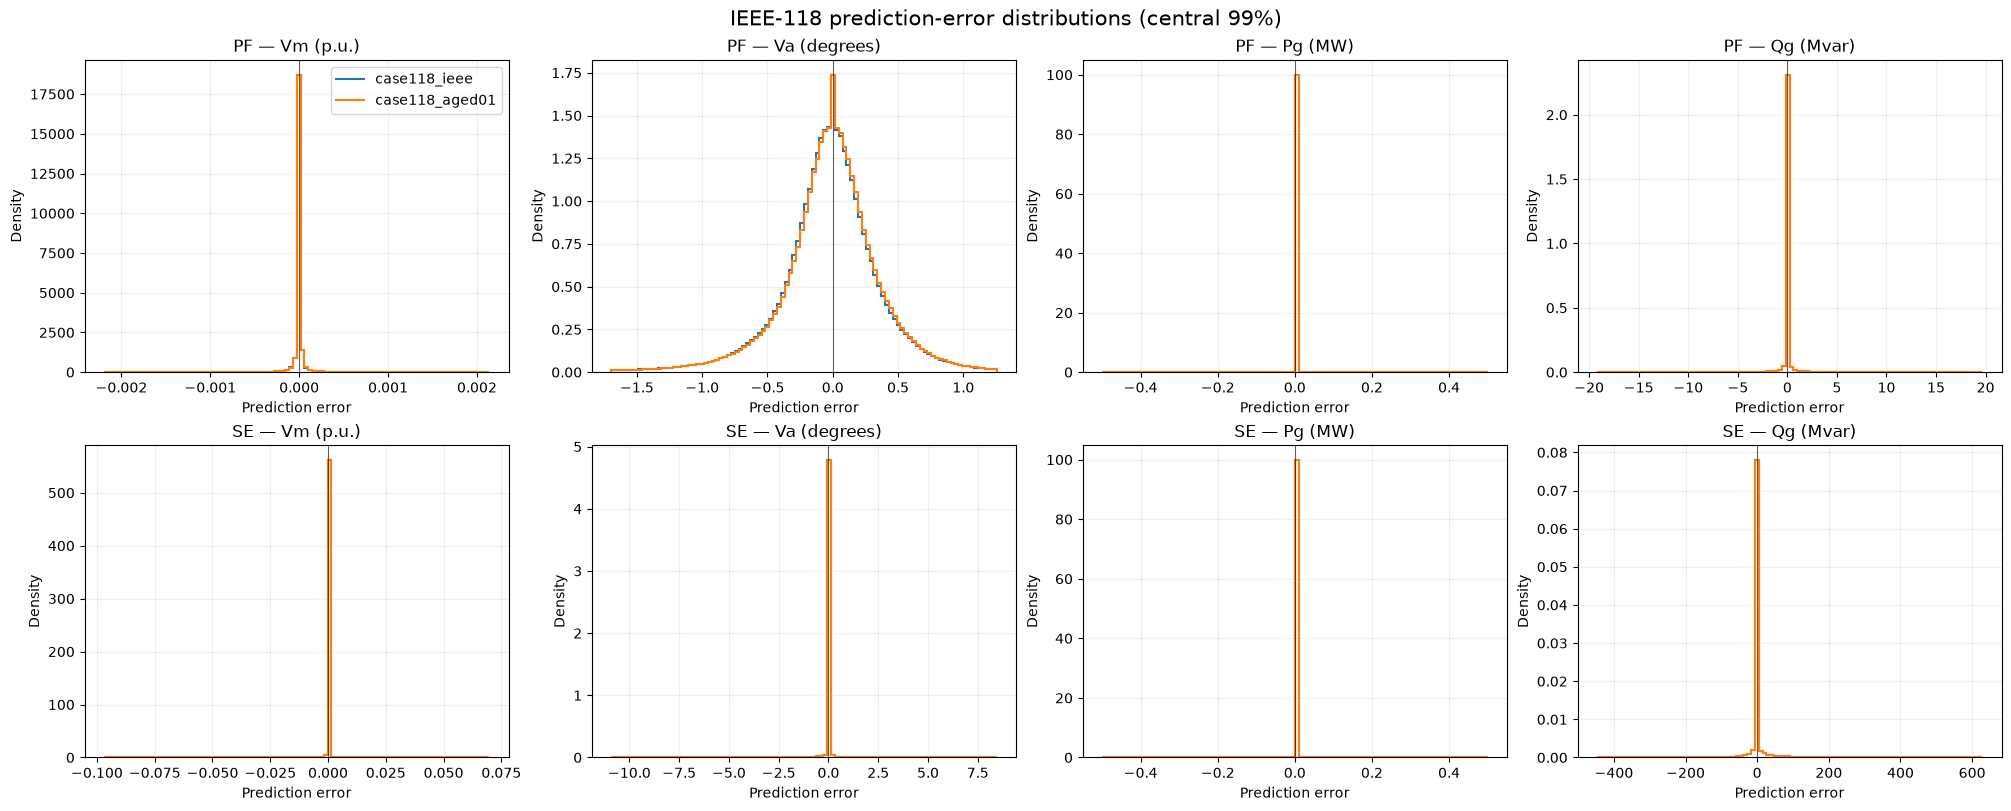

In [9]:
error_specs = {
    "Vm (p.u.)": ("vm_gt_pu", "vm_pred_pu"),
    "Va (degrees)": ("va_gt_deg", "va_pred_deg"),
    "Pg (MW)": ("pg_gt_mw", "pg_pred_mw"),
    "Qg (Mvar)": ("qg_gt_mvar", "qg_pred_mvar"),
}
colors = {"case118_ieee": "tab:blue", "case118_aged01": "tab:orange"}
fig, axes = plt.subplots(2, 4, figsize=(20, 8), constrained_layout=True)

for row, task in enumerate(("pf", "se")):
    for col, (label, (gt_column, pred_column)) in enumerate(error_specs.items()):
        ax = axes[row, col]
        errors = {}
        for dataset_name in datasets:
            values = pd.read_parquet(
                output_paths[dataset_name, task],
                columns=[gt_column, pred_column],
            )
            error = (values[pred_column] - values[gt_column]).to_numpy()
            errors[dataset_name] = error[np.isfinite(error)]

        lower = min(np.quantile(error, 0.005) for error in errors.values())
        upper = max(np.quantile(error, 0.995) for error in errors.values())
        if lower == upper:
            lower, upper = lower - 0.5, upper + 0.5
        bins = np.linspace(lower, upper, 101)
        for dataset_name, error in errors.items():
            density, _ = np.histogram(error, bins=bins, density=True)
            ax.stairs(
                density,
                bins,
                label=dataset_name,
                color=colors[dataset_name],
                linewidth=1.5,
            )
        ax.axvline(0, color="black", linewidth=0.8, alpha=0.6)
        ax.set_title(f"{task.upper()} — {label}")
        ax.set_xlabel("Prediction error")
        ax.set_ylabel("Density")
        ax.grid(alpha=0.2)
        if row == 0 and col == 0:
            ax.legend()

histogram_path = OUTPUT_DIR / "error_histograms.png"
fig.suptitle("IEEE-118 prediction-error distributions (central 99%)", fontsize=15)
fig.savefig(histogram_path, dpi=200, bbox_inches="tight")
print(f"Saved histogram to {histogram_path}")
plt.show()

## 6. Hidden-aging experiment: aged state with original line impedance

This experiment represents an aged physical network whose changed line impedances are unknown to the operator. Bus/generator measurements, branch flows, and all ground-truth targets come from `case118_aged01`, while the model receives the matched original network's line-admittance features. Graphkit does not feed raw `r` and `x` to the model; their effect is encoded by the four directional admittance columns `Yff`/`Yft` (and `Ytt`/`Ytf` on reverse edges), so only those normalized columns are replaced. Branch status, topology, limits, tap settings, and every measured or target quantity remain from the aged case.

Cases are paired by load-scenario ID and scenario signature (active branches/generators plus the randomized generator costs), rather than by dataset row number. Aged cases with no exact original counterpart are excluded and reported below. The final histogram compares the correctly specified aged run with the hidden-aging run on exactly the same retained scenarios.


In [12]:
ORIGINAL_NAME = "case118_ieee"
AGED_NAME = "case118_aged01"
HIDDEN_AGING_NAME = "case118_aged01_original_impedance"
original_dataset = datasets[ORIGINAL_NAME]
aged_dataset = datasets[AGED_NAME]
edge_type = ("bus", "connects", "bus")
admittance_columns = slice(YFF_TT_R, YFT_TF_I + 1)


def group_indices_by_load(dataset):
    groups = {}
    for index, load_index in enumerate(dataset.load_scenarios.tolist()):
        groups.setdefault(int(load_index), []).append(index)
    return groups


def scenario_signature(graph):
    branch_on = (graph[edge_type].edge_attr[:, B_ON] > 0.5).to(torch.uint8)
    generator_on = (graph["gen"].x[:, G_ON] > 0.5).to(torch.uint8)
    generator_cost = graph["gen"].x[:, C0_H : C2_H + 1]
    return (
        branch_on.cpu().numpy().tobytes(),
        generator_on.cpu().numpy().tobytes(),
        generator_cost.cpu().numpy().tobytes(),
    )


original_groups = group_indices_by_load(original_dataset)
aged_groups = group_indices_by_load(aged_dataset)
hidden_aging_pairs = {}


def match_in_order(aged_indices, original_indices):
    """Return the longest order-preserving match of scenario signatures."""
    aged_signatures = [scenario_signature(aged_dataset[i]) for i in aged_indices]
    original_signatures = [
        scenario_signature(original_dataset[i]) for i in original_indices
    ]
    n_aged, n_original = len(aged_indices), len(original_indices)
    lengths = np.zeros((n_aged + 1, n_original + 1), dtype=np.int8)
    for i in range(n_aged):
        for j in range(n_original):
            if aged_signatures[i] == original_signatures[j]:
                lengths[i + 1, j + 1] = lengths[i, j] + 1
            else:
                lengths[i + 1, j + 1] = max(lengths[i, j + 1], lengths[i + 1, j])
    pairs = {}
    i, j = n_aged, n_original
    while i and j:
        if aged_signatures[i - 1] == original_signatures[j - 1]:
            pairs[aged_indices[i - 1]] = original_indices[j - 1]
            i -= 1
            j -= 1
        elif lengths[i - 1, j] >= lengths[i, j - 1]:
            i -= 1
        else:
            j -= 1
    return pairs


for load_index, aged_indices in aged_groups.items():
    original_indices = original_groups.get(load_index, [])
    hidden_aging_pairs.update(match_in_order(aged_indices, original_indices))

hidden_aging_indices = sorted(hidden_aging_pairs)
excluded_count = len(aged_dataset) - len(hidden_aging_indices)
print(f"Matched {len(hidden_aging_indices):,} aged scenarios")
print(f"Excluded {excluded_count:,} aged scenarios without an original counterpart")

KeyboardInterrupt: 

In [ ]:
def prepare_hidden_aging_graph(dataset, aged_index, task):
    aged_graph = dataset[aged_index]
    original_index = hidden_aging_pairs[aged_index]
    original_graph = original_dataset[original_index]

    if not torch.equal(
        aged_graph[edge_type].edge_index, original_graph[edge_type].edge_index
    ):
        raise ValueError(f"Edge ordering differs for aged scenario {aged_index}")
    if scenario_signature(aged_graph) != scenario_signature(original_graph):
        raise ValueError(f"Scenario pairing differs for aged scenario {aged_index}")
    if not np.isclose(float(aged_graph.baseMVA), float(original_graph.baseMVA)):
        raise ValueError(f"baseMVA differs for aged scenario {aged_index}")

    # Both graphs are already normalized with the same saved normalizer.
    # Replace only the impedance-derived model inputs; retain all aged targets.
    aged_graph[edge_type].edge_attr[:, admittance_columns] = original_graph[
        edge_type
    ].edge_attr[:, admittance_columns]
    return apply_task_transform(aged_graph, aged_index, task)


hidden_aging_paths = {
    (HIDDEN_AGING_NAME, task): predict_all(
        HIDDEN_AGING_NAME,
        aged_dataset,
        task,
        indices=hidden_aging_indices,
        graph_preparer=prepare_hidden_aging_graph,
    )
    for task in ("pf", "se")
}
output_paths.update(hidden_aging_paths)
print(f"Successfully evaluated {len(hidden_aging_indices):,} matched scenarios")

In [ ]:
comparison_colors = {
    "Aged, correct impedance": "tab:orange",
    "Aged, original impedance": "tab:red",
}
fig, axes = plt.subplots(2, 4, figsize=(20, 8), constrained_layout=True)
retained_indices = set(hidden_aging_indices)

for row, task in enumerate(("pf", "se")):
    for col, (label, (gt_column, pred_column)) in enumerate(error_specs.items()):
        columns = key_columns + [gt_column, pred_column]
        aged_known = pd.read_parquet(output_paths[AGED_NAME, task], columns=columns)
        aged_known = aged_known[aged_known["dataset_index"].isin(retained_indices)]
        aged_hidden = pd.read_parquet(
            output_paths[HIDDEN_AGING_NAME, task], columns=columns
        )
        aged_known = aged_known.reset_index(drop=True)
        aged_hidden = aged_hidden.reset_index(drop=True)
        if not aged_known[key_columns].equals(aged_hidden[key_columns]):
            raise ValueError(f"Comparison row keys differ for {task} {label}")
        if not np.allclose(aged_known[gt_column], aged_hidden[gt_column]):
            raise ValueError(f"Ground truths differ for {task} {label}")

        errors = {
            "Aged, correct impedance": (
                aged_known[pred_column] - aged_known[gt_column]
            ).to_numpy(),
            "Aged, original impedance": (
                aged_hidden[pred_column] - aged_hidden[gt_column]
            ).to_numpy(),
        }
        errors = {name: values[np.isfinite(values)] for name, values in errors.items()}
        lower = min(np.quantile(error, 0.005) for error in errors.values())
        upper = max(np.quantile(error, 0.995) for error in errors.values())
        if lower == upper:
            lower, upper = lower - 0.5, upper + 0.5
        bins = np.linspace(lower, upper, 101)
        ax = axes[row, col]
        for name, error in errors.items():
            density, _ = np.histogram(error, bins=bins, density=True)
            ax.stairs(
                density, bins, label=name, color=comparison_colors[name], linewidth=1.5
            )
        ax.axvline(0, color="black", linewidth=0.8, alpha=0.6)
        ax.set_title(f"{task.upper()} — {label}")
        ax.set_xlabel("Prediction error")
        ax.set_ylabel("Density")
        ax.grid(alpha=0.2)
        if row == 0 and col == 0:
            ax.legend()

hidden_histogram_path = OUTPUT_DIR / "hidden_aging_error_histograms.png"
fig.suptitle(
    "Effect of unknown aged line impedance (matched scenarios, central 99%)",
    fontsize=15,
)
fig.savefig(hidden_histogram_path, dpi=200, bbox_inches="tight")
print(f"Saved histogram to {hidden_histogram_path}")
plt.show()